# Traffic Case Study Model

Dataset: `traffic_case_study.xlsx`

### Note: Claude Opus 5.5 was used as an assistant

## Load the raw data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
case_study = pd.read_excel("traffic_case_study.xlsx")
case_study.shape

(600, 26)

In [3]:
case_study.head()

,AUTOMOBILE_COUNT,SPEED_LIMIT,URBAN_RURAL,URBAN,YOUNG_DRIVER,COLLISION_TYPE,LANE_COUNT,BICYCLE_COUNT,BUS_COUNT,ILLUMINATION,...,DRUGGED_DRIVER,FATAL_OR_SUSP_SERIOUS_INJ,FATIGUE_ASLEEP,HIT_FIXED_OBJECT,LANE_DEPARTURE,MATURE_DRIVER,OVERTURNED,SCHOOL_ZONE,SPEEDING_RELATED,WET_ROAD
0,1,25.0,4,1.0,0.0,2,2.0,1,0.0,1,...,0,0,0,0,0,0,0,0,0,0
1,1,35.0,4,1.0,0.0,2,4.0,1,0.0,1,...,0,0,0,0,0,0,0,0,0,0
2,0,25.0,1,0.0,1.0,7,2.0,0,0.0,1,...,0,0,0,1,1,0,0,0,0,0
3,0,35.0,4,1.0,0.0,7,2.0,0,0.0,1,...,1,0,0,1,1,0,0,0,1,0
4,3,35.0,4,1.0,0.0,2,2.0,0,0.0,1,...,0,0,0,0,1,1,0,0,0,0


## Missing values

In [4]:
nulls = case_study.isnull().sum()
nulls = nulls[nulls > 0].sort_values(ascending=False)
print(len(nulls), "of", case_study.shape[1], "fields have null values\n")
print(nulls.to_string())

5 of 26 fields have null values

SPEED_LIMIT     60
URBAN           60
YOUNG_DRIVER    60
LANE_COUNT      60
BUS_COUNT       60


## Handling the missing values

The case-study rows are the first 600 rows of `features.xls` (every value they share matches), so the missing values are recovered from there.
Every fatal / serious crash is missing `SPEED_LIMIT`, so a mean or a "was missing" flag would give away the outcome. Recovering the real values avoids that.

| Field | Method |
|---|---|
| `SPEED_LIMIT` | Copied from `features.xls` |
| `LANE_COUNT` | Copied from `features.xls` |
| `BUS_COUNT` | Copied from `features.xls` |
| `YOUNG_DRIVER` | From the driver counts in `features.xls`: any driver aged 16–20 = 1 |
| `URBAN` | From `URBAN_RURAL`: 1 (rural) = 0, otherwise 1 |

In [5]:
source = pd.read_excel("features.xls").iloc[:600]

shared = [c for c in case_study.columns if c in source.columns]
both = case_study[shared].notna() & source[shared].notna()
print("Values that differ between the two files:", int(((case_study[shared] != source[shared]) & both).sum().sum()))

df = case_study.copy()
for col in ["SPEED_LIMIT", "LANE_COUNT", "BUS_COUNT"]:
    df[col] = df[col].fillna(source[col])
young_counts = ["DRIVER_COUNT_16YR", "DRIVER_COUNT_17YR", "DRIVER_COUNT_18YR", "DRIVER_COUNT_19YR", "DRIVER_COUNT_20YR"]
df["YOUNG_DRIVER"] = df["YOUNG_DRIVER"].fillna((source[young_counts].sum(axis=1) > 0).astype(float))
df["URBAN"] = df["URBAN"].fillna((df["URBAN_RURAL"] != 1).astype(float))

print("Missing values left:", df.isnull().sum().sum())

Values that differ between the two files: 0
Missing values left: 0


## Data Cleaning

Drop complete duplicates: rows that are exact copies of another row.

In [6]:
n_before = len(df)
df = df[~df.duplicated()].reset_index(drop=True)
print(f"Dropped {n_before - len(df)} duplicate rows → {len(df)} rows, {int(df['FATAL_OR_SUSP_SERIOUS_INJ'].sum())} fatal / serious")

Dropped 122 duplicate rows → 478 rows, 25 fatal / serious


## Feature selection

### Step 1: Prepare the features

- Leave out the outcome `FATAL_OR_SUSP_SERIOUS_INJ`
- Drop `URBAN_RURAL` (same as `URBAN`)
- Split `COLLISION_TYPE` and `ILLUMINATION` into one yes/no column per code

In [7]:
TARGET = "FATAL_OR_SUSP_SERIOUS_INJ"
collision_names = {0: "NON_COLLISION", 1: "REAR_END", 2: "HEAD_ON", 3: "BACKING", 4: "ANGLE",
                   5: "SIDESWIPE_SAME_DIR", 6: "SIDESWIPE_OPP_DIR", 7: "HIT_FIXED_OBJECT",
                   8: "HIT_NON_MOTORIST", 98: "OTHER"}
light_names = {1: "DAYLIGHT", 2: "DARK_NO_LIGHTS", 3: "DARK_LIGHTS", 4: "DUSK", 5: "DAWN", 6: "DARK_UNKNOWN"}

y = df[TARGET]
X = df.drop(columns=[TARGET, "URBAN_RURAL", "COLLISION_TYPE", "ILLUMINATION"])
X = X.join(pd.get_dummies(df["COLLISION_TYPE"].map(collision_names), prefix="COLL").astype(int))
X = X.join(pd.get_dummies(df["ILLUMINATION"].map(light_names), prefix="LIGHT").astype(int))
X.shape

(478, 37)

### Step 2: Multicollinearity check

- Yes/no pair: chi-square test, strength = Cramér's V
- Pair with a count or number: Pearson's r
- Strength above 0.8: drop one of the pair · 0.7–0.8: marginal (keep both for now) · below 0.7: keep both

In [8]:
from itertools import combinations
import numpy as np
from scipy.stats import chi2_contingency, pearsonr

def association_pairs(X):
    yes_no = [c for c in X if X[c].between(0, 1).all()]
    rows = []
    for a, b in combinations(X.columns, 2):
        if a in yes_no and b in yes_no:
            both = X[a].isin([0, 1]) & X[b].isin([0, 1])          # skip mean-imputed values
            table = pd.crosstab(X.loc[both, a], X.loc[both, b])
            chi2, p, _, _ = chi2_contingency(table, correction=False)
            strength, test = np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1))), "Cramér's V"
        else:
            r, p = pearsonr(X[a], X[b])
            strength, test = abs(r), "Pearson |r|"
        rows.append({"Feature A": a, "Feature B": b, "Test": test, "Strength": strength, "p-value": p})
    return pd.DataFrame(rows).sort_values("Strength", ascending=False).reset_index(drop=True)

pairs = association_pairs(X)
print(len(pairs), "pairs tested |", (pairs["Strength"] > 0.8).sum(), "above 0.8 |",
      pairs["Strength"].between(0.7, 0.8).sum(), "marginal (0.7–0.8)")

666 pairs tested | 3 above 0.8 | 0 marginal (0.7–0.8)


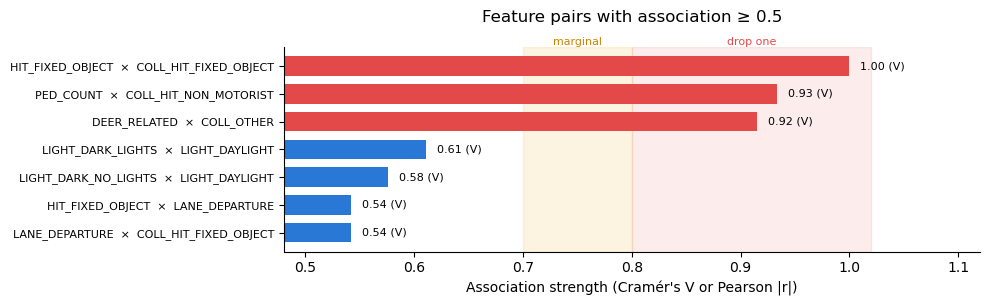

In [9]:
import matplotlib.pyplot as plt

def plot_pairs(pairs, title, min_strength=0.5):
    top = pairs[pairs["Strength"] >= min_strength].iloc[::-1]
    colors = ["#e34948" if s > 0.8 else "#eda100" if s >= 0.7 else "#2a78d6" for s in top["Strength"]]
    fig, ax = plt.subplots(figsize=(10, 0.28 * len(top) + 1.2))
    ax.axvspan(0.7, 0.8, color="#eda100", alpha=0.12)
    ax.axvspan(0.8, 1.02, color="#e34948", alpha=0.10)
    ax.barh(top["Feature A"] + "  ×  " + top["Feature B"], top["Strength"], color=colors, height=0.7)
    for i, (s, t) in enumerate(zip(top["Strength"], top["Test"])):
        ax.text(s + 0.01, i, f"{s:.2f} ({'V' if t.startswith('Cram') else 'r'})", va="center", fontsize=8)
    ax.set_xlim(min_strength - 0.02, 1.12)
    ax.set_xlabel("Association strength (Cramér's V or Pearson |r|)")
    ax.set_title(title, pad=18)
    ax.text(0.75, 1.0, "marginal", ha="center", va="bottom", fontsize=8, color="#c98500", transform=ax.get_xaxis_transform())
    ax.text(0.91, 1.0, "drop one", ha="center", va="bottom", fontsize=8, color="#e34948", transform=ax.get_xaxis_transform())
    ax.tick_params(axis="y", labelsize=8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    plt.tight_layout()
    plt.show()

plot_pairs(pairs, "Feature pairs with association ≥ 0.5")

**Pairs above 0.8: which one is dropped.** Rule: keep the original field over the collision-type column built from a code.

| Dropped | Kept | Reason |
|---|---|---|
| `COLL_HIT_FIXED_OBJECT` | `HIT_FIXED_OBJECT` | Identical |
| `COLL_HIT_NON_MOTORIST` | `PED_COUNT` | Same crashes (pedestrian hit) |
| `COLL_OTHER` | `DEER_RELATED` | Deer crashes are coded "other"; "other" is not defined |

In [10]:
X = X.drop(columns=["COLL_HIT_FIXED_OBJECT", "COLL_HIT_NON_MOTORIST", "COLL_OTHER"])

pairs_after = association_pairs(X)
print(X.shape[1], "features left | strongest remaining pair:", round(pairs_after["Strength"].max(), 2))

34 features left | strongest remaining pair: 0.61


### Step 3: SelectKBest (chi-square)

- Score every feature by its chi-square association with `FATAL_OR_SUSP_SERIOUS_INJ` and keep the top 10
- Chi-square says how strongly a feature is linked to the outcome, not in which direction, so the severe rate when the feature = yes is shown next to it

In [11]:
from sklearn.feature_selection import SelectKBest, chi2

print(f"Overall severe rate: {y.mean():.1%}")
selector = SelectKBest(chi2, k=10).fit(X, y)

ranking = pd.DataFrame({
    "Chi-square": selector.scores_,
    "p-value": selector.pvalues_,
    "Severe rate when yes": [y[X[c] == 1].mean() if X[c].isin([0, 1]).all() else np.nan for c in X],   # yes/no features only
}, index=X.columns).sort_values("Chi-square", ascending=False)
ranking["Selected"] = ranking.index.isin(X.columns[selector.get_support()])

top10 = ranking.index[ranking["Selected"]].tolist()
ranking.head(20).style.format({"Chi-square": "{:.2f}", "p-value": "{:.4f}", "Severe rate when yes": "{:.1%}"}, na_rep="–")

Overall severe rate: 5.2%


,Chi-square,p-value,Severe rate when yes,Selected
UNBELTED_OCC_COUNT,28.79,0.0000,–,True
MOTORCYCLE_COUNT,16.71,0.0000,23.1%,True
OVERTURNED,15.77,0.0001,25.0%,True
COLL_ANGLE,6.00,0.0143,9.8%,True
FATIGUE_ASLEEP,4.40,0.0359,20.0%,True
COLL_REAR_END,4.30,0.0380,0.0%,True
LIGHT_DARK_NO_LIGHTS,2.48,0.1151,0.0%,True
CURVED_ROAD,2.35,0.1253,1.3%,True
PED_COUNT,2.32,0.1280,14.3%,True
DRUGGED_DRIVER,2.32,0.1280,14.3%,True


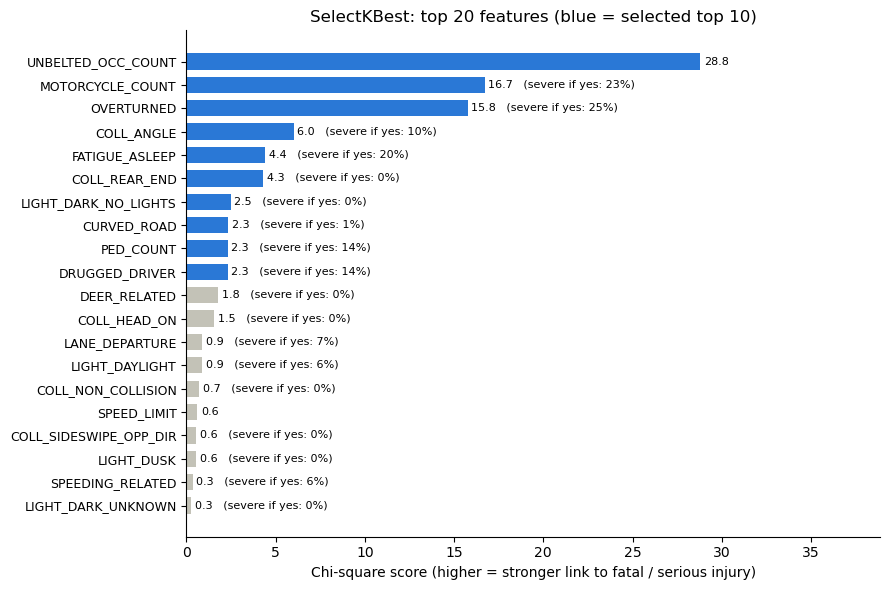

In [12]:
top = ranking.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.index, top["Chi-square"], color=["#2a78d6" if s else "#c3c2b7" for s in top["Selected"]], height=0.7)
for i, (score, rate) in enumerate(zip(top["Chi-square"], top["Severe rate when yes"])):
    ax.text(score + 0.2, i, f"{score:.1f}   (severe if yes: {rate:.0%})" if pd.notna(rate) else f"{score:.1f}", va="center", fontsize=8)
ax.set_xlabel("Chi-square score (higher = stronger link to fatal / serious injury)")
ax.set_title("SelectKBest: top 20 features (blue = selected top 10)")
ax.set_xlim(0, top["Chi-square"].max() * 1.35)
ax.tick_params(axis="y", labelsize=9)
for s in ["top", "right"]:
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.show()

## Model

- Features: the top 10 from SelectKBest
- Logistic regression with an L2 penalty (`C = 1.0`); features are standardized first
- Class imbalance handled with `class_weight="balanced"`
- 5-fold stratified cross-validation, repeated 10 times (50 test folds)

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import RepeatedStratifiedKFold, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
CLASS_LABELS = ["Not severe", "Fatal / serious injury"]
CLASS_COLORS = ["#a9a8a2", "#e34948"]

In [14]:
X_model = X[top10]
y_model = y

### Class imbalance

Few crashes are severe, so an unweighted model would predict "not severe" for everyone. Balanced class weights give each severe crash more weight, so both classes count equally in training.

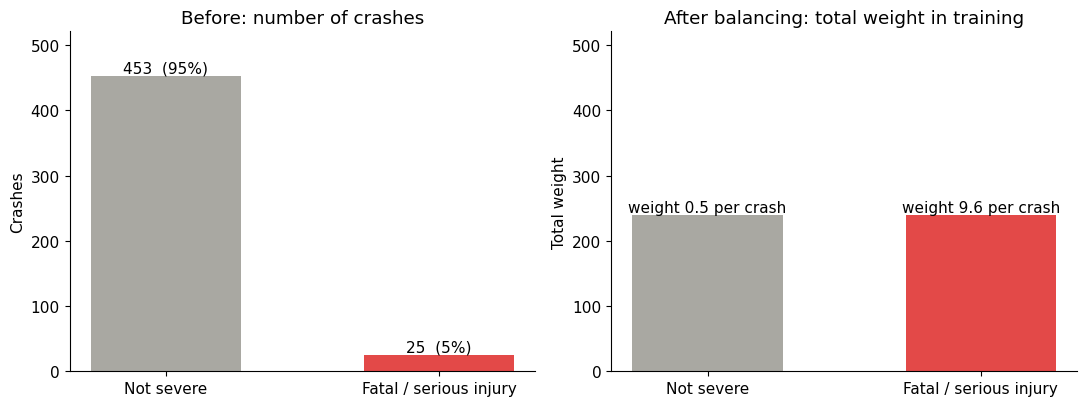

In [15]:
counts = y_model.value_counts().sort_index()
weight_per_crash = len(y_model) / (2 * counts)          # what class_weight="balanced" uses

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
bars = axes[0].bar(CLASS_LABELS, counts, color=CLASS_COLORS, width=0.55)
for bar, n in zip(bars, counts):
    axes[0].text(bar.get_x() + bar.get_width() / 2, n, f"{n}  ({n / len(y_model):.0%})", ha="center", va="bottom")
axes[0].set_title("Before: number of crashes")
axes[0].set_ylabel("Crashes")

bars = axes[1].bar(CLASS_LABELS, counts * weight_per_crash, color=CLASS_COLORS, width=0.55)
for bar, w in zip(bars, weight_per_crash):
    axes[1].text(bar.get_x() + bar.get_width() / 2, bar.get_height(), f"weight {w:.1f} per crash", ha="center", va="bottom")
axes[1].set_title("After balancing: total weight in training")
axes[1].set_ylabel("Total weight")
for ax in axes:
    ax.set_ylim(0, max(counts) * 1.15)
plt.tight_layout()
plt.show()

### Cross-validated results

In [16]:
model = make_pipeline(StandardScaler(),
                      LogisticRegression(C=1.0, class_weight="balanced", max_iter=1000))   # L2 penalty is the default
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=42)
scores = cross_validate(model, X_model, y_model, cv=cv,
                        scoring=["accuracy", "precision", "recall", "f1", "roc_auc"])

metric_names = {"accuracy": "Accuracy", "precision": "Precision", "recall": "Recall", "f1": "F1", "roc_auc": "ROC AUC"}
results = pd.DataFrame({"Mean": [scores[f"test_{m}"].mean() for m in metric_names],
                        "Std": [scores[f"test_{m}"].std() for m in metric_names]},
                       index=metric_names.values()).round(3)
results

,Mean,Std
Accuracy,0.858,0.034
Precision,0.239,0.068
Recall,0.760,0.215
F1,0.360,0.098
ROC AUC,0.848,0.117


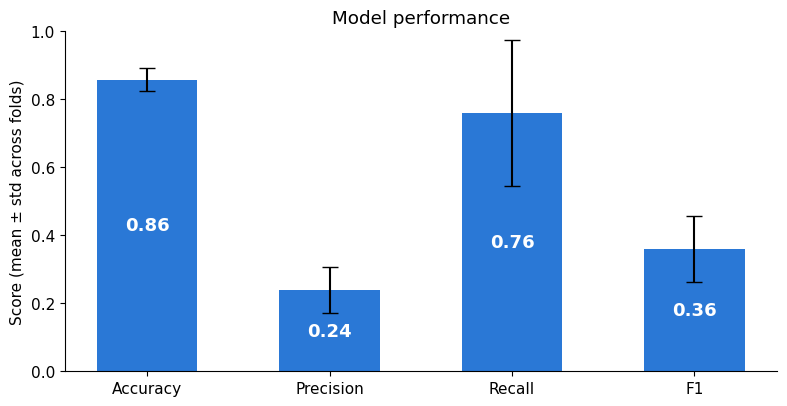

In [17]:
main = results.loc[["Accuracy", "Precision", "Recall", "F1"]]
fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.bar(main.index, main["Mean"], yerr=main["Std"], capsize=6, color="#2a78d6", width=0.55)
for bar, v in zip(bars, main["Mean"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v / 2, f"{v:.2f}", ha="center", va="center",
            color="white", fontsize=13, fontweight="bold")
ax.set_ylim(0, 1)
ax.set_ylabel("Score (mean ± std across folds)")
ax.set_title("Model performance")
plt.tight_layout()
plt.show()

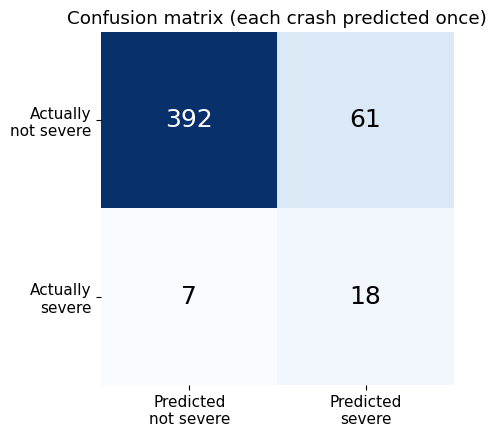

In [18]:
pred = cross_val_predict(model, X_model, y_model, cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
cm = confusion_matrix(y_model, pred)

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.imshow(cm, cmap="Blues")
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, v, ha="center", va="center", fontsize=18, color="white" if v > cm.max() / 2 else "black")
ax.set_xticks([0, 1], ["Predicted\nnot severe", "Predicted\nsevere"])
ax.set_yticks([0, 1], ["Actually\nnot severe", "Actually\nsevere"])
ax.set_title("Confusion matrix (each crash predicted once)")
ax.spines[:].set_visible(False)
plt.tight_layout()
plt.show()

### Feature importance

Coefficients of the model fitted on all rows. Features are standardized, so the bar lengths are comparable: red raises the risk of a fatal / serious injury, blue lowers it.

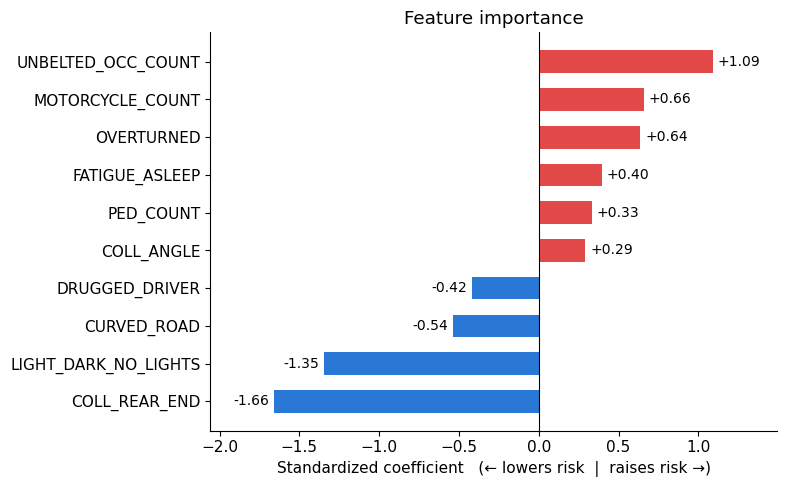

In [19]:
model.fit(X_model, y_model)
coef = pd.Series(model[-1].coef_[0], index=X_model.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(coef.index, coef, color=["#e34948" if c > 0 else "#2a78d6" for c in coef], height=0.6)
for i, c in enumerate(coef):
    ax.text(c + (0.03 if c > 0 else -0.03), i, f"{c:+.2f}", va="center", ha="left" if c > 0 else "right", fontsize=10)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlim(coef.min() - 0.4, coef.max() + 0.4)
ax.set_xlabel("Standardized coefficient   (← lowers risk  |  raises risk →)")
ax.set_title("Feature importance")
plt.tight_layout()
plt.show()

### VIF check

VIF above 5 would signal multicollinearity.

In [20]:
X_const = sm.add_constant(X_model.astype(float))
vif = pd.DataFrame({"VIF": [variance_inflation_factor(X_const.values, i) for i in range(1, X_const.shape[1])]},
                   index=X_model.columns).round(2).sort_values("VIF", ascending=False)
vif

,VIF
COLL_ANGLE,1.26
COLL_REAR_END,1.22
CURVED_ROAD,1.11
OVERTURNED,1.08
LIGHT_DARK_NO_LIGHTS,1.08
FATIGUE_ASLEEP,1.06
PED_COUNT,1.05
UNBELTED_OCC_COUNT,1.05
DRUGGED_DRIVER,1.04
MOTORCYCLE_COUNT,1.03


## Results

**Features (10):** UNBELTED_OCC_COUNT, MOTORCYCLE_COUNT, OVERTURNED, COLL_ANGLE, FATIGUE_ASLEEP, COLL_REAR_END, LIGHT_DARK_NO_LIGHTS, CURVED_ROAD, PED_COUNT, DRUGGED_DRIVER

| Accuracy | Precision | Recall | F1 |
|---|---|---|---|
| 0.86 | 0.24 | 0.76 | 0.36 |

- The model catches 76% of fatal / serious crashes; about 1 in 4 of its "severe" flags is correct
- Strongest risk factors: unbelted occupants, motorcycle, overturned vehicle. Rear-end crashes were never severe
- `DRUGGED_DRIVER` has a negative coefficient: both severe drugged-driver crashes also had unbelted occupants and an overturned vehicle, which already explain them
- Only 25 severe crashes, so results vary a lot between folds (recall ± 0.22)
- All VIFs ≈ 1: no multicollinearity